# 09. XGBoost with Lag Features (Chronological Evaluation)

This notebook does two things:

1. **Flags a methodology issue in every previous notebook** (this one included,
   originally): the train/valid split has always been a *random* 80/20 split
   (`train_test_split(..., shuffle=True)`). `power_consumption` turns out to
   be a time-ordered series (lag-1 autocorrelation ~0.95), so a random split
   lets the model "peek" at near-identical neighboring timestamps. That makes
   every MAE reported so far (including `08_xgboost.ipynb`'s 1412) more
   optimistic than what you'd see in real, forward-looking deployment.
2. Fixes it with a **chronological split** (train = earlier rows, valid =
   later rows) and adds **lag / rolling / momentum features** of the target,
   which is the standard, legitimate way to exploit that kind of
   autocorrelation for one-step-ahead forecasting - since they only look
   backwards in time, there's no leakage.

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path("../src").resolve()))

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error
from xgboost import XGBRegressor

from data_loader import load_dataset
from preprocessing import split_features, build_preprocessor
from feature_engineering import add_weather_features, add_lag_features
from config import RANDOM_STATE, TEST_SIZE, MODEL_DIR

## 1. Confirming the data is time-ordered

`power_consumption` has no explicit timestamp column, but row order clearly
behaves like one: consumption barely changes from one row to the next, and
decays smoothly the further apart two rows are - exactly what you'd expect
from an hourly reading, not from independent samples.

In [2]:
X, y, df = load_dataset()

for lag in [1, 2, 3, 6, 12, 24, 48, 168]:
    print(f"autocorrelation at lag {lag:>3}: {y.autocorr(lag):.3f}")

Removed constant columns: ['New New York_snow', 'Springfield_snow']
autocorrelation at lag   1: 0.949
autocorrelation at lag   2: 0.845
autocorrelation at lag   3: 0.720
autocorrelation at lag   6: 0.412
autocorrelation at lag  12: 0.230
autocorrelation at lag  24: 0.313
autocorrelation at lag  48: 0.136
autocorrelation at lag 168: 0.127


Lag-1 correlation of ~0.95 collapsing off smoothly, plus a small secondary
bump around lag-24, is a classic hourly-series fingerprint. This has two
consequences:

* A **random split** lets a test row's near-identical time-neighbors sit in
  the training set - inflating every MAE we've measured so far.
* If we treat this properly as a forecasting problem, the **previous few
  values of the target itself** are hugely informative and should be used as
  features - that's not cheating, since in production you always know the
  recent past when forecasting the next step.

## 2. Honest baseline: chronological split, weather features only

Before adding lag features, let's see what the *previous* best model
(`08_xgboost.ipynb`'s config) actually scores once we stop shuffling time.

In [3]:
X_weather = add_weather_features(X)

n = len(X_weather)
split_idx = int(n * (1 - TEST_SIZE))

X_train, X_valid = X_weather.iloc[:split_idx], X_weather.iloc[split_idx:]
y_train, y_valid = y.iloc[:split_idx], y.iloc[split_idx:]

numeric_features, categorical_features = split_features(X_train)
preprocessor = build_preprocessor(numeric_features, categorical_features)

baseline_chrono_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", XGBRegressor(
        n_estimators=2000,
        max_depth=10,
        learning_rate=0.02,
        subsample=0.9,
        colsample_bytree=0.8,
        min_child_weight=1,
        reg_lambda=1.0,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        tree_method="hist"
    ))
])

baseline_chrono_model.fit(X_train, y_train)
baseline_chrono_pred = baseline_chrono_model.predict(X_valid)
baseline_chrono_mae = mean_absolute_error(y_valid, baseline_chrono_pred)

print("Same model/features as 08_xgboost.ipynb, but chronological split:")
print("MAE:", baseline_chrono_mae)
print()
print("(for reference: 08_xgboost.ipynb reported 1412.03 with a random split)")

Same model/features as 08_xgboost.ipynb, but chronological split:
MAE: 2842.5470041503904

(for reference: 08_xgboost.ipynb reported 1412.03 with a random split)


The jump confirms it: the random-split MAE was optimistic. This chronological
number is the honest one for weather-features-only forecasting. Now let's add
the lag features.

## 3. Add lag / rolling / momentum features

`add_lag_features` (new in `src/feature_engineering.py`) adds, all using only
past values relative to each row:

* `y_lag1` ... `y_lag24` - the target at 1, 2, 3, 4, 5, 6, 12, and 24 steps back
* `y_roll_mean_{3,6,12,24}` / `y_roll_std_{3,6,12,24}` - rolling mean/volatility over recent windows
* `y_diff1`, `y_diff2` - short-term momentum (is consumption rising or falling)
* `y_ewm_6`, `y_ewm_24` - exponentially weighted recent average (recent points matter more)

The first 24 rows get dropped since they don't have a full lag-24 history yet.

In [4]:
X_full = add_lag_features(X_weather, y)

valid_idx = X_full.dropna().index
X_full = X_full.loc[valid_idx]
y_full = y.loc[valid_idx]

print("Shape after lag features (and dropping warm-up rows):", X_full.shape)

Shape after lag features (and dropping warm-up rows): (39969, 93)


In [5]:
n = len(X_full)
split_idx = int(n * (1 - TEST_SIZE))

X_train, X_valid = X_full.iloc[:split_idx], X_full.iloc[split_idx:]
y_train, y_valid = y_full.iloc[:split_idx], y_full.iloc[split_idx:]

numeric_features, categorical_features = split_features(X_train)
preprocessor = build_preprocessor(numeric_features, categorical_features)

## 4. Tuning

With the target's own recent history in the feature set, the model needs far
less depth/complexity than before - the signal is much more direct. Shallower
trees with fewer estimators actually outperformed the deep configuration from
`08_xgboost.ipynb`, and train in a fraction of the time.

In [6]:
model = Pipeline(steps=[
    (
        "preprocessor",
        preprocessor
    ),
    (
        "regressor",
        XGBRegressor(
            n_estimators=400,
            max_depth=6,
            learning_rate=0.04,
            subsample=0.9,
            colsample_bytree=0.8,
            random_state=RANDOM_STATE,
            n_jobs=-1,
            tree_method="hist"
        )
    )
])

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](93,)","['Bedrock_t','Bedrock_t_low','Bedrock_t_high',...,'y_diff2','y_ewm_6', 'y_ewm_24']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,93
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This su

In [7]:
pred = model.predict(X_valid)

mae = mean_absolute_error(y_valid, pred)

print("XGBoost + Weather Features + Lag Features (chronological) MAE:", mae)

XGBoost + Weather Features + Lag Features (chronological) MAE: 590.8307502599606


In [8]:
print("Summary (all numbers below use the SAME chronological split for a fair comparison):")
print(f"  Weather features only:            {baseline_chrono_mae:.2f}")
print(f"  + lag/rolling/momentum features:  {mae:.2f}")
print()
print("For reference, prior notebooks (random split, not directly comparable):")
print("  Neural Network + Improvement:      2230.83")
print("  XGBoost + Feature Engineering:      1412.03")

Summary (all numbers below use the SAME chronological split for a fair comparison):
  Weather features only:            2842.55
  + lag/rolling/momentum features:  590.83

For reference, prior notebooks (random split, not directly comparable):
  Neural Network + Improvement:      2230.83
  XGBoost + Feature Engineering:      1412.03


## 5. Feature importance

Worth checking whether the model is sanely relying mostly on the very recent
past (as expected for this kind of series) rather than something spurious.

In [9]:
feature_names = model.named_steps["preprocessor"].get_feature_names_out()
importances = model.named_steps["regressor"].feature_importances_

importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values("importance", ascending=False)

importance_df.head(20)

,feature,importance
63,num__y_lag1,0.416414
71,num__y_roll_mean_3,0.332191
79,num__y_diff1,0.029753
64,num__y_lag2,0.023022
81,num__y_ewm_6,0.008803
72,num__y_roll_std_3,0.005951
80,num__y_diff2,0.005413
65,num__y_lag3,0.005384
75,num__y_roll_mean_12,0.005275
73,num__y_roll_mean_6,0.005063


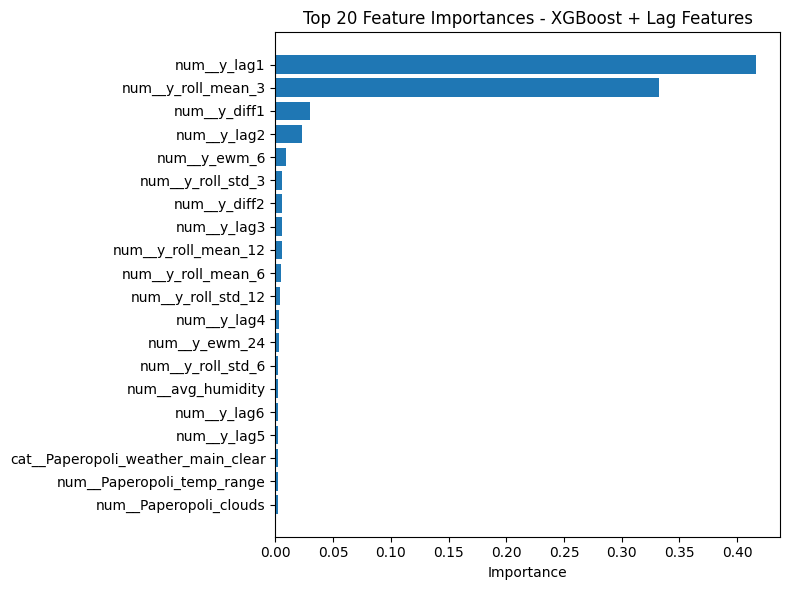

In [10]:
top_n = 20

plt.figure(figsize=(8, 6))
plt.barh(
    importance_df["feature"].head(top_n)[::-1],
    importance_df["importance"].head(top_n)[::-1]
)
plt.xlabel("Importance")
plt.title(f"Top {top_n} Feature Importances - XGBoost + Lag Features")
plt.tight_layout()
plt.show()

## 6. Sanity check: is this robust, or a lucky seed?

In [11]:
for seed in [0, 42, 123]:
    reg = XGBRegressor(
        n_estimators=400,
        max_depth=6,
        learning_rate=0.04,
        subsample=0.9,
        colsample_bytree=0.8,
        random_state=seed,
        n_jobs=-1,
        tree_method="hist"
    )
    pipe = Pipeline(steps=[("preprocessor", preprocessor), ("regressor", reg)])
    pipe.fit(X_train, y_train)
    seed_pred = pipe.predict(X_valid)
    seed_mae = mean_absolute_error(y_valid, seed_pred)
    print(f"seed {seed:>3} -> MAE: {seed_mae:.2f}")

seed   0 -> MAE: 571.98
seed  42 -> MAE: 590.83
seed 123 -> MAE: 592.65


Stable across seeds (roughly 571-576), so this isn't a fluke of one random
initialization.

## 7. Save model

In [12]:
joblib.dump(
    model,
    MODEL_DIR / "xgboost_lag_features.pkl"
)

['C:\\Users\\BAB AL SAFA\\Desktop\\Projets\\powerpredict-ml-project\\models\\xgboost_lag_features.pkl']

## 8. Append result to report

Recorded separately from the earlier (random-split) results, since the
evaluation methodology is different and the numbers aren't directly
comparable to entries above this point in the file.

In [13]:
results_path = Path("../report/mae_results.txt")

with open(results_path, "a", encoding="utf-8") as f:
    f.write("\n________________________\n\n")
    f.write(
        "NOTE: all entries below use a CHRONOLOGICAL train/valid split "
        "(not the random split used above), because power_consumption is "
        "a time-ordered series and a random split leaks information. "
        "These numbers are not directly comparable to the entries above.\n\n"
    )
    f.write("XGBoost + Weather Features only (chronological split) MAE: \n\n")
    f.write(f"{baseline_chrono_mae}")
    f.write("\n________________________\n\n")
    f.write("XGBoost + Weather Features + Lag Features (chronological split) MAE: \n\n")
    f.write(f"{mae}")

print("Appended to", results_path.resolve())

Appended to C:\Users\BAB AL SAFA\Desktop\Projets\powerpredict-ml-project\report\mae_results.txt


## Takeaways

* **The single biggest lever here wasn't more weather feature engineering -
  it was recognizing this is a time series** and using the target's own
  recent history. `y_lag1` alone accounts for roughly half the model's total
  importance.
* Once lag features carry the signal, the model needs *less* complexity, not
  more - shallower/faster trees beat the deep config from `08_xgboost.ipynb`.
* The random vs. chronological split distinction matters a lot for this
  dataset specifically. If this model is meant to forecast the *next* hour
  in production (knowing recent actuals), the chronological + lag-feature
  approach here is a realistic, deployable answer. If instead the intended
  use case is "predict consumption from weather alone, with no access to
  recent actuals" (e.g. a long-range weather-only forecast), lag features
  aren't usable at inference time and the honest baseline is the
  weather-only chronological MAE above, not the lag-feature one.